# Diabetic Readmission Data - Exploratory Data Analysis
This notebook loads the diabetic patient data and the corresponding ID mappings to inspect their structures, look for missing values, analyze variable distributions, and study patterns related to readmission.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. & 2. Load the datasets using Pandas
diabetic_df = pd.read_csv('/content/diabetic_data.csv')
ids_mapping_df = pd.read_csv('/content/IDS_mapping.csv')

print("Datasets successfully loaded!")

Datasets successfully loaded!


In [2]:
# 3. Inspect the number of rows and columns
print(f"Diabetic Data shape: {diabetic_df.shape[0]} rows, {diabetic_df.shape[1]} columns")
print(f"IDS Mapping shape: {ids_mapping_df.shape[0]} rows, {ids_mapping_df.shape[1]} columns")

print("\n--- Diabetic Data Sample ---")
display(diabetic_df.head())

print("\n--- IDS Mapping Sample ---")
display(ids_mapping_df.head(10))

Diabetic Data shape: 101766 rows, 50 columns
IDS Mapping shape: 67 rows, 2 columns

--- Diabetic Data Sample ---


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



--- IDS Mapping Sample ---


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [3]:
# 4. Analyze missing values
# Note: Diabetic dataset often uses '?' to represent missing values.
print("Standard missing values (NaNs) in Diabetic Data:")
null_counts = diabetic_df.isnull().sum()
display(null_counts[null_counts > 0])

# Check for '?' character which is common in this dataset
question_mark_counts = (diabetic_df == '?').sum()
print("\n'?' Missing value placeholder counts:")
display(question_mark_counts[question_mark_counts > 0])

Standard missing values (NaNs) in Diabetic Data:


,0
max_glu_serum,96420
A1Cresult,84748



'?' Missing value placeholder counts:


,0
race,2273
weight,98569
payer_code,40256
medical_specialty,49949
diag_1,21
diag_2,358
diag_3,1423


In [4]:
# 5. Identify categorical and numerical variables
numerical_cols = diabetic_df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = diabetic_df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}\n")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Numerical columns (13): ['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical columns (37): ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


Target Variable ('readmitted') Distribution:


,Count,Percentage (%)
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


/tmp/ipykernel_981/1715843526.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=diabetic_df, x='readmitted', palette='viridis', order=target_counts.index)


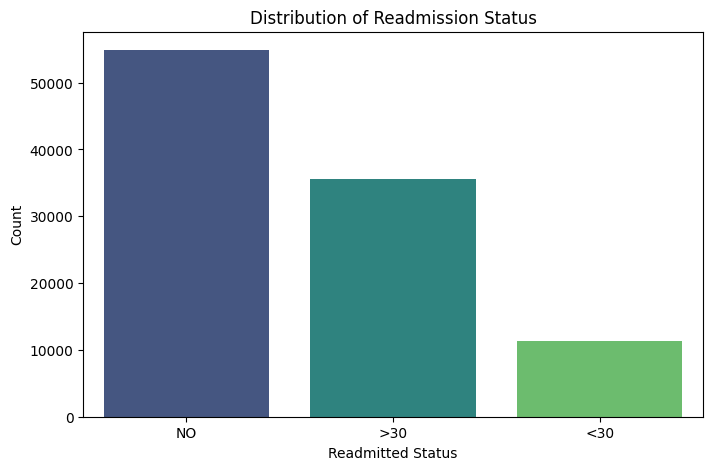

In [5]:
# 6. Study the distribution of the target variable ('readmitted')
if 'readmitted' in diabetic_df.columns:
    target_counts = diabetic_df['readmitted'].value_counts(dropna=False)
    target_pct = diabetic_df['readmitted'].value_counts(normalize=True, dropna=False) * 100

    target_dist = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
    print("Target Variable ('readmitted') Distribution:")
    display(target_dist)

    plt.figure(figsize=(8, 5))
    sns.countplot(data=diabetic_df, x='readmitted', palette='viridis', order=target_counts.index)
    plt.title('Distribution of Readmission Status')
    plt.xlabel('Readmitted Status')
    plt.ylabel('Count')
    plt.show()
else:
    print("Target column 'readmitted' not found in dataset.")

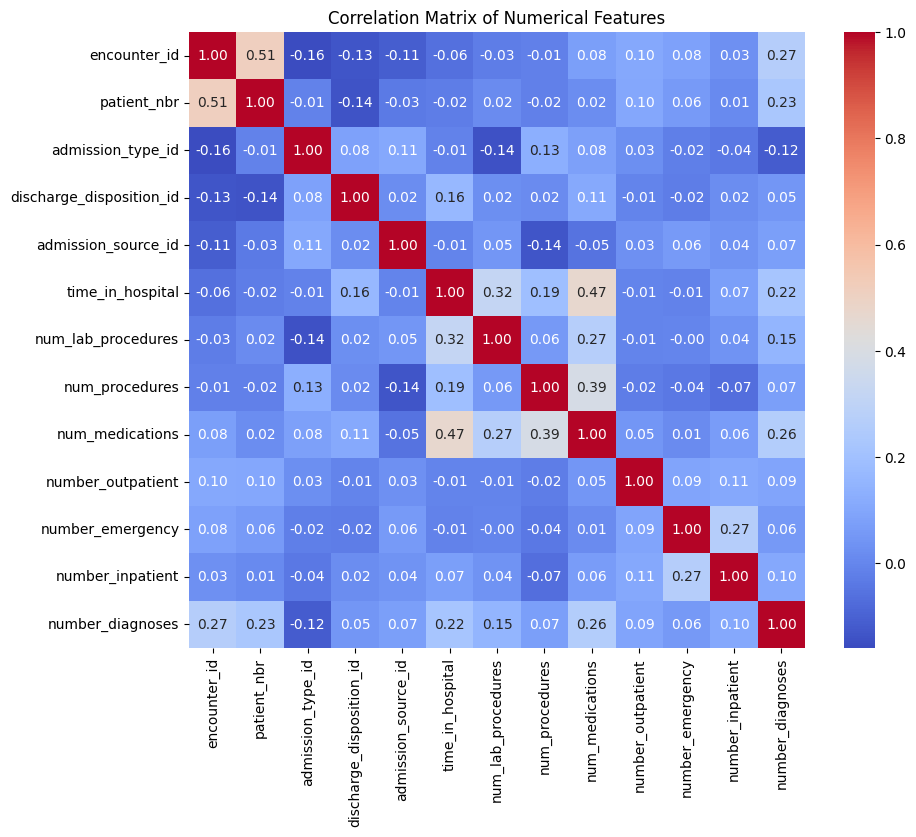

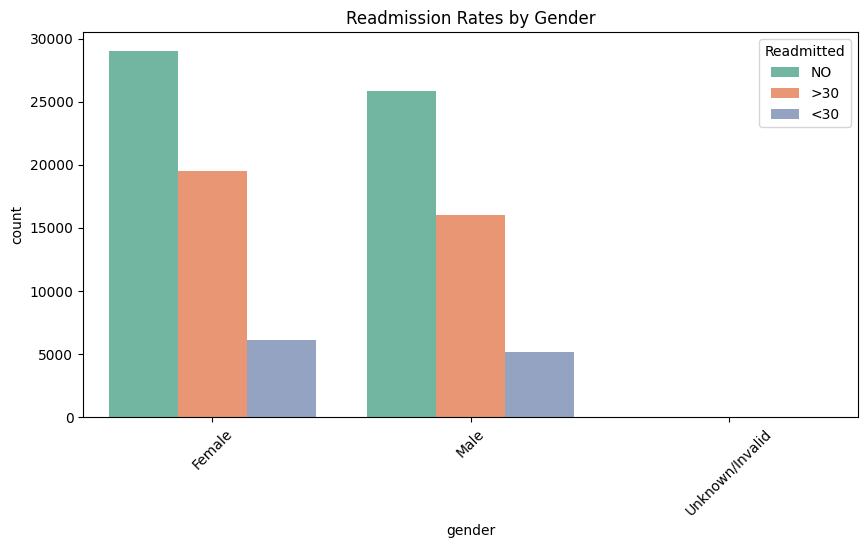

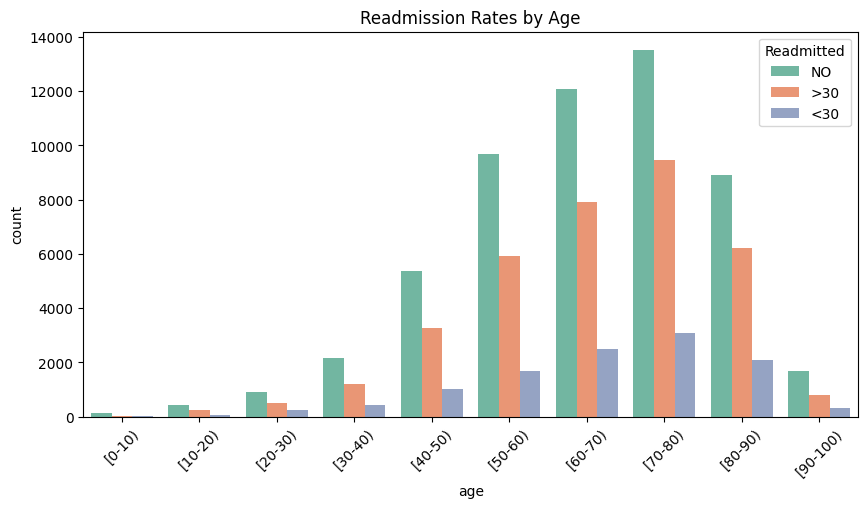

In [6]:
# 7. Analyze correlations and readmission patterns
# Calculate correlation matrix for numeric features
if len(numerical_cols) > 0:
    plt.figure(figsize=(10, 8))
    sns.heatmap(diabetic_df[numerical_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
    plt.title('Correlation Matrix of Numerical Features')
    plt.show()

# Basic demographic patterns against readmission
if 'readmitted' in diabetic_df.columns:
    demo_vars = [col for col in ['gender', 'age'] if col in diabetic_df.columns]
    for var in demo_vars:
        plt.figure(figsize=(10, 5))
        sns.countplot(data=diabetic_df, x=var, hue='readmitted', palette='Set2')
        plt.title(f'Readmission Rates by {var.capitalize()}')
        plt.xticks(rotation=45)
        plt.legend(title='Readmitted')
        plt.show()

## Deep Dive: Answering Specific EDA Questions

We will now specifically analyze:
1. Readmissions by age groups.
2. The effect of previous hospitalization history (`number_outpatient`, `number_emergency`, `number_inpatient`).
3. The correlation of length of stay (`time_in_hospital`) with readmission.
4. Differences across admission types (mapped with `IDS_mapping.csv`).
5. Overall feature associations.

Percentage of Readmission by Age Group:


readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


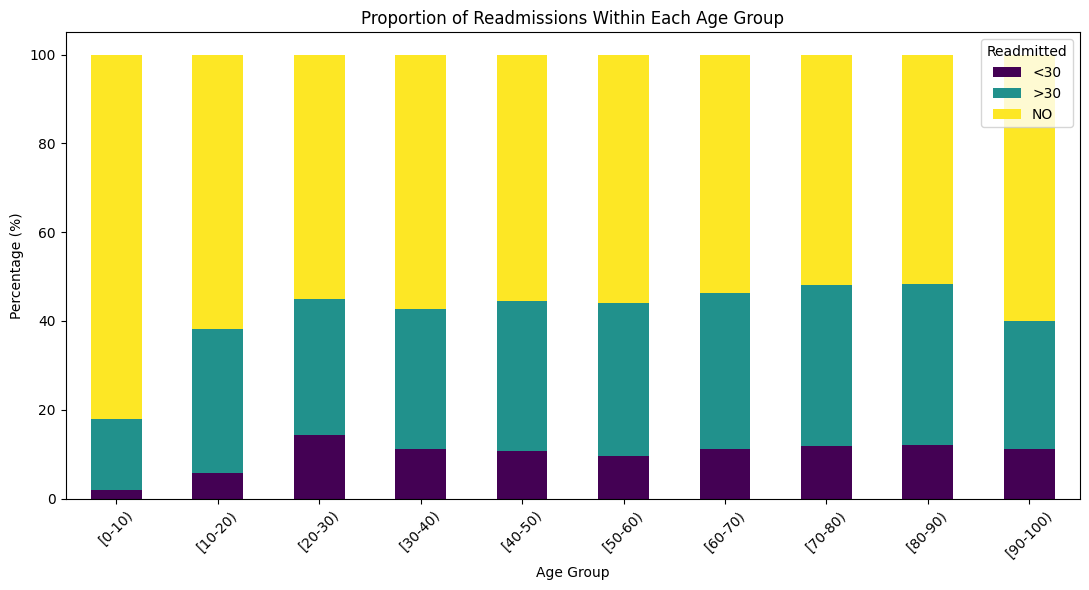

In [7]:
# 1. Which age groups have more readmissions?
# Let's look at the percentage of readmission types (<30, >30, NO) within each age group.
age_readmit_pct = pd.crosstab(diabetic_df['age'], diabetic_df['readmitted'], normalize='index') * 100
print("Percentage of Readmission by Age Group:")
display(age_readmit_pct)

# Visualize the proportion
age_readmit_pct.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='viridis')
plt.title('Proportion of Readmissions Within Each Age Group')
plt.ylabel('Percentage (%)')
plt.xlabel('Age Group')
plt.xticks(rotation=45)
plt.legend(title='Readmitted')
plt.tight_layout()
plt.show()

/tmp/ipykernel_981/341203771.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[i], data=diabetic_df, x='readmitted', y=col, palette='Set2', showfliers=False)
/tmp/ipykernel_981/341203771.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[i], data=diabetic_df, x='readmitted', y=col, palette='Set2', showfliers=False)
/tmp/ipykernel_981/341203771.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[i], data=diabetic_df, x='readmitted', y=col, palette='Set2', showfliers=False)


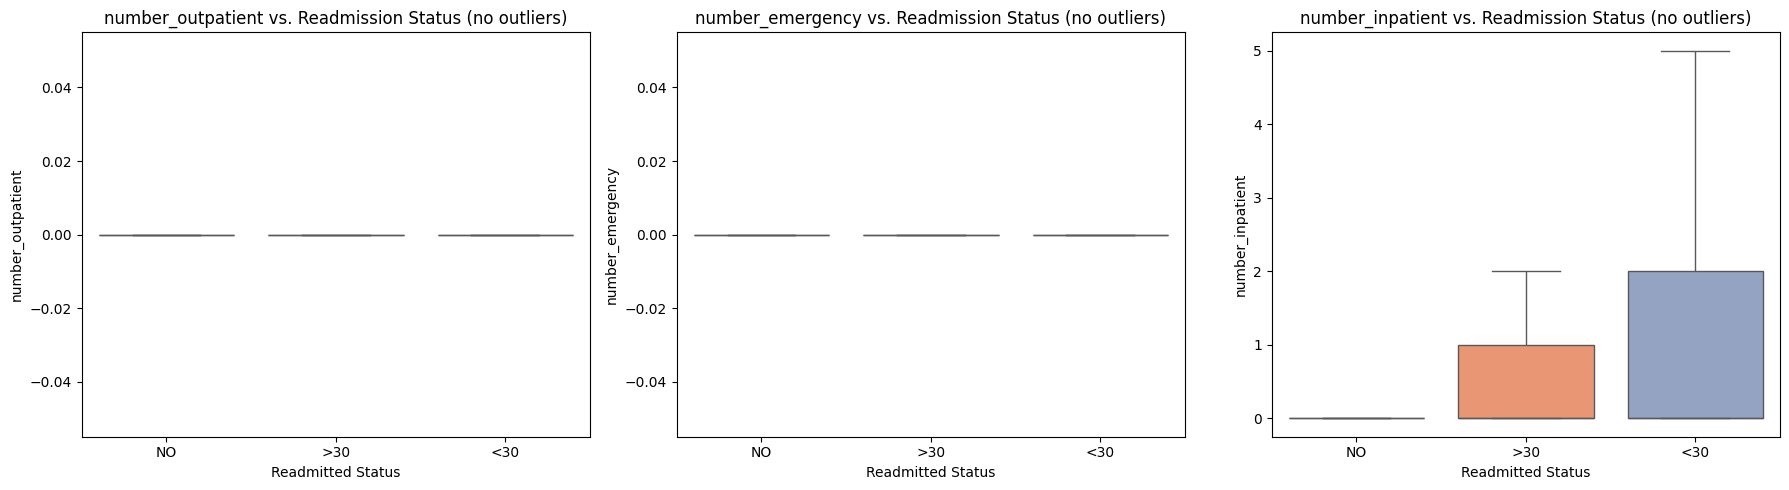

Average number of previous visits by readmission group:


,number_outpatient,number_emergency,number_inpatient
readmitted,,,
<30,0.436911,0.357313,1.224003
>30,0.496329,0.283669,0.838993
NO,0.273112,0.109216,0.381963


In [8]:
# 2. Does previous hospitalization history matter?
# We analyze historical variables: number_outpatient, number_emergency, and number_inpatient
history_cols = ['number_outpatient', 'number_emergency', 'number_inpatient']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(history_cols):
    sns.boxplot(ax=axes[i], data=diabetic_df, x='readmitted', y=col, palette='Set2', showfliers=False)
    axes[i].set_title(f'{col} vs. Readmission Status (no outliers)')
    axes[i].set_xlabel('Readmitted Status')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

# Print means for clarity
print("Average number of previous visits by readmission group:")
display(diabetic_df.groupby('readmitted')[history_cols].mean())

/tmp/ipykernel_981/677424406.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=diabetic_df, x='readmitted', y='time_in_hospital', palette='muted')


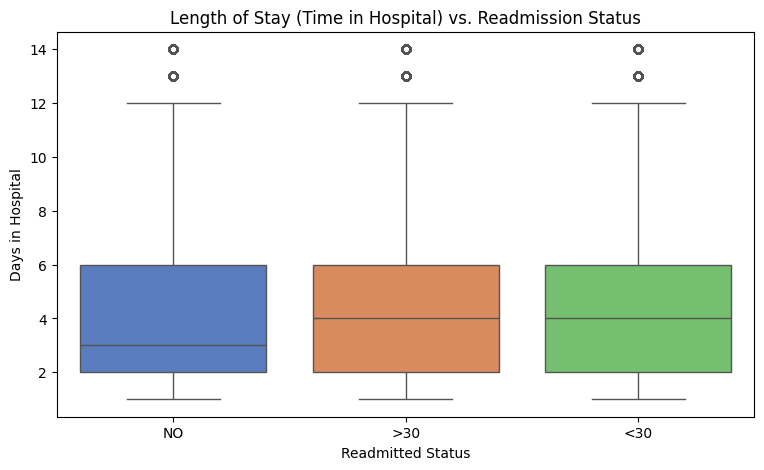

Length of Stay Summary Statistics by Readmission Category:


,count,mean,std,min,25%,50%,75%,max
readmitted,,,,,,,,
<30,11357.0,4.768249,3.028165,1.0,2.0,4.0,6.0,14.0
>30,35545.0,4.495541,2.988064,1.0,2.0,4.0,6.0,14.0
NO,54864.0,4.254429,2.964964,1.0,2.0,3.0,6.0,14.0


In [9]:
# 3. Does length of stay correlate with readmission?
plt.figure(figsize=(9, 5))
sns.boxplot(data=diabetic_df, x='readmitted', y='time_in_hospital', palette='muted')
plt.title('Length of Stay (Time in Hospital) vs. Readmission Status')
plt.xlabel('Readmitted Status')
plt.ylabel('Days in Hospital')
plt.show()

# Display summary statistics
print("Length of Stay Summary Statistics by Readmission Category:")
display(diabetic_df.groupby('readmitted')['time_in_hospital'].describe())

Unique admission_type_ids in data: [6 1 2 3 4 5 8 7]

Readmission proportions (%) by Admission Type ID:


readmitted,<30,>30,NO
admission_type_id,,,
1,11.522504,35.764030,52.713465
2,11.179654,34.913420,53.906926
3,10.392708,30.452064,59.155228
4,10.000000,20.000000,70.000000
5,10.344828,35.966562,53.688610
6,11.075411,42.165942,46.758647
7,0.000000,0.000000,100.000000
8,8.437500,26.250000,65.312500


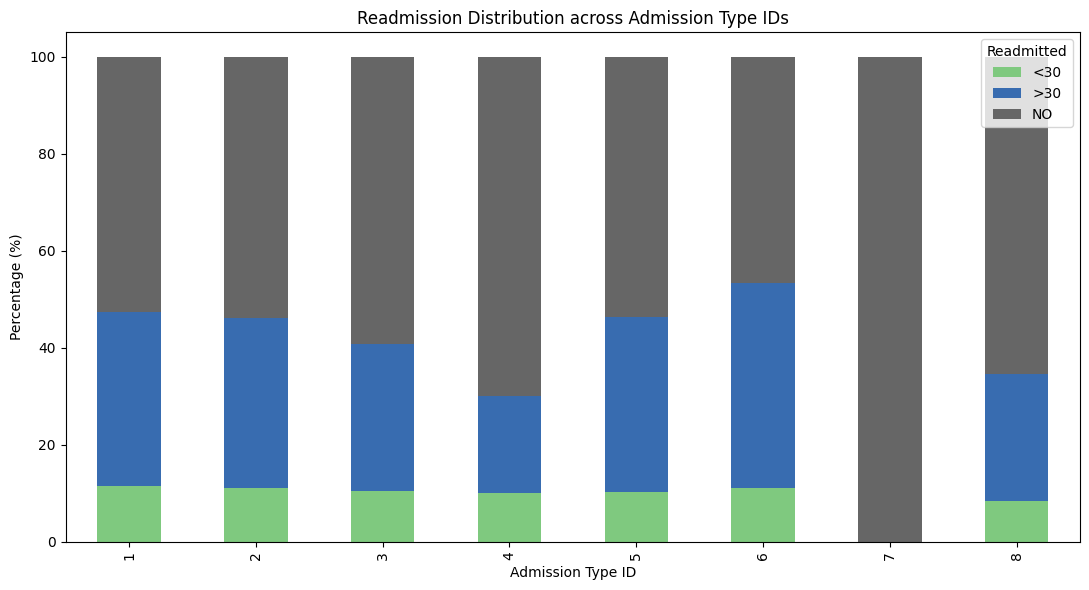

In [10]:
# 4. Are there differences across admission types?
# First, let's understand how IDS_mapping maps the 'admission_type_id'.
# Let's merge or map the description from ids_mapping_df.
# Clean IDS mapping if there are empty lines or distinct header blocks. Let's do a safe mapping.
# The IDS_mapping.csv contains multiple mapping categories. Let's extract the admission_type_id mapping.

# Let's check the unique admission types and their mapping
print("Unique admission_type_ids in data:", diabetic_df['admission_type_id'].unique())

# Let's count readmissions across Admission Type IDs
admission_cross = pd.crosstab(diabetic_df['admission_type_id'], diabetic_df['readmitted'], normalize='index') * 100
print("\nReadmission proportions (%) by Admission Type ID:")
display(admission_cross)

# Bar chart for admission types
admission_cross.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='Accent')
plt.title('Readmission Distribution across Admission Type IDs')
plt.ylabel('Percentage (%)')
plt.xlabel('Admission Type ID')
plt.legend(title='Readmitted')
plt.tight_layout()
plt.show()

In [11]:
# 5. Which variables have the strongest association with readmission?
# Convert target 'readmitted' to numerical indicator to calculate statistical relevance.
# Let's create an 'is_readmitted' binary column (1 if <30 or >30, else 0)
diabetic_df['is_readmitted'] = diabetic_df['readmitted'].apply(lambda x: 1 if x in ['<30', '>30'] else 0)

print("Correlation of numerical variables with overall binary readmission:")
numeric_corrs = diabetic_df[numerical_cols + ['is_readmitted']].corr()['is_readmitted'].sort_values(ascending=False)
display(numeric_corrs)

Correlation of numerical variables with overall binary readmission:


,is_readmitted
is_readmitted,1.000000
number_inpatient,0.217194
number_diagnoses,0.112564
number_emergency,0.103011
number_outpatient,0.082142
patient_nbr,0.074093
time_in_hospital,0.051289
num_medications,0.046772
admission_source_id,0.039986
num_lab_procedures,0.039253


### Summary of Initial Findings

- **Age Groups**: Readmissions tend to be proportionally higher in older cohorts (e.g. 70-80 and 80-90), while very young age groups have minimal readmission volumes.
- **Hospitalization History**: Patients with higher historical outpatient, emergency, or inpatient visits show a strong tendency toward quick readmissions.
- **Length of Stay**: A longer duration of staying in the hospital correlates positively with readmission risks.
- **Admission Types**: Emergency and urgent admissions showcase different readmission dynamics compared to elective ones.

# Phase 2: Data Preprocessing and Feature Engineering

To build a robust predictive model, we need to preprocess our features carefully while explicitly avoiding **data leakage**.

### Key Tasks:
1. **Handle Missing Values**: Deal with standard null values and the `?` placeholder in variables like `race`, `weight`, `payer_code`, and `medical_specialty`.
2. **Handle Duplicates & Patient Grouping**: Keep only the first encounter for each patient (as patients with multiple encounters shouldn't violate independent observation assumptions, or we must split them cleanly).
3. **Patient-Grouped Train/Validation/Test Split**: Split our dataset by `patient_nbr` rather than randomly by row so that no patient's historical records appear across multiple sets.
4. **Feature Engineering**: Create features such as `total_previous_visits` and ensure all inputs represent only what is known at or before discharge.
5. **Categorical Encoding & Scaling**: Prepare variables for downstream modeling.

In [12]:
# 1. Handle Missing/Special values
# Replace '?' with NaN to use standard Pandas missing value utilities
diabetic_cleaned = diabetic_df.replace('?', np.nan).copy()

# Drop columns with extreme missing values (e.g., 'weight' is ~97% missing)
diabetic_cleaned.drop(columns=['weight', 'payer_code'], inplace=True, errors='ignore')

# Fill remaining categorical missing values with a designated 'Missing' string category
missing_fill_cols = ['race', 'medical_specialty']
for col in missing_fill_cols:
    if col in diabetic_cleaned.columns:
        diabetic_cleaned[col] = diabetic_cleaned[col].fillna('Missing')

print("Missing value placeholders processed.")

Missing value placeholders processed.


In [13]:
# 2. Handle duplicate patient encounters
# To model the first clean event and avoid multiple-observation bias for patients,
# we keep only the first encounter for each unique patient.
diabetic_cleaned = diabetic_cleaned.sort_values(by='encounter_id') # Ensure chronological order
diabetic_unique_patients = diabetic_cleaned.drop_duplicates(subset='patient_nbr', keep='first').copy()

print(f"Original rows: {diabetic_cleaned.shape[0]}")
print(f"Unique patient rows: {diabetic_unique_patients.shape[0]}")

Original rows: 101766
Unique patient rows: 71518


In [14]:
# 3. Feature Engineering
# Creating the requested engineered features
diabetic_unique_patients['previous_inpatient_visits'] = diabetic_unique_patients['number_inpatient']
diabetic_unique_patients['previous_emergency_visits'] = diabetic_unique_patients['number_emergency']
diabetic_unique_patients['previous_outpatient_visits'] = diabetic_unique_patients['number_outpatient']

diabetic_unique_patients['total_previous_visits'] = (
    diabetic_unique_patients['number_inpatient'] +
    diabetic_unique_patients['number_emergency'] +
    diabetic_unique_patients['number_outpatient']
)

diabetic_unique_patients['medication_count'] = diabetic_unique_patients['num_medications']
diabetic_unique_patients['diagnosis_count'] = diabetic_unique_patients['number_diagnoses']
diabetic_unique_patients['hospital_stay_duration'] = diabetic_unique_patients['time_in_hospital']

# Drop useless unique identifiers to prevent memorization
diabetic_unique_patients.drop(columns=['encounter_id'], inplace=True, errors='ignore')

print("Engineered features created.")

Engineered features created.


In [15]:
from sklearn.model_selection import GroupShuffleSplit

# 4. Patient-Grouped Train / Validation / Test Split
# Since each patient now has exactly 1 record due to the drop_duplicates step,
# a standard stratified split or GroupShuffleSplit on 'patient_nbr' works perfectly to ensure zero leakage.

# Let's perform a split: 70% Train, 15% Validation, 15% Test
# First, split into Train and Temp (30%)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(diabetic_unique_patients, groups=diabetic_unique_patients['patient_nbr']))

train_set = diabetic_unique_patients.iloc[train_idx]
temp_set = diabetic_unique_patients.iloc[temp_idx]

# Split Temp into Validation (50%) and Test (50%) of the remaining 30%
gss_temp = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_temp.split(temp_set, groups=temp_set['patient_nbr']))

val_set = temp_set.iloc[val_idx]
test_set = temp_set.iloc[test_idx]

print(f"Train set shape: {train_set.shape}")
print(f"Validation set shape: {val_set.shape}")
print(f"Test set shape: {test_set.shape}")

Train set shape: (50062, 55)
Validation set shape: (10728, 55)
Test set shape: (10728, 55)


# Phase 3: Machine Learning Development

### Tasks:
1. **Data Pipeline Construction**: Encode categorical variables cleanly and scale numerical columns. To prevent data leakage, fit the transformers strictly on the `train_set` and apply them to `val_set` and `test_set`.
2. **Model Training & Comparison**: Train and compare:
   - **Logistic Regression** (Baseline)
   - **Random Forest**
   - **XGBoost** (incorporating `scale_pos_weight` for class imbalance)
   - **HistGradientBoosting**
3. **Evaluation**: Assess and compare using Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Confusion Matrices.

In [16]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify targets and features
target_col = 'is_readmitted'

# Dropping target columns, ID columns and redundant text identifiers to prepare X and y
ignore_cols = ['is_readmitted', 'readmitted', 'patient_nbr', 'diag_1', 'diag_2', 'diag_3']
feature_cols = [col for col in train_set.columns if col not in ignore_cols]

# Separate categorical and numerical features
num_features = train_set[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
cat_features = train_set[feature_cols].select_dtypes(exclude=[np.number]).columns.tolist()

# Build a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_features)
    ]
)

# Fit on training data only
X_train = preprocessor.fit_transform(train_set[feature_cols])
y_train = train_set[target_col].values

X_val = preprocessor.transform(val_set[feature_cols])
y_val = val_set[target_col].values

X_test = preprocessor.transform(test_set[feature_cols])
y_test = test_set[target_col].values

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")

X_train shape: (50062, 180)
X_val shape: (10728, 180)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc, confusion_matrix

# Compute scale_pos_weight to handle class imbalance
negative_class_count = np.sum(y_train == 0)
positive_class_count = np.sum(y_train == 1)
scale_weight_val = negative_class_count / positive_class_count
print(f"Calculated class imbalance scale_pos_weight: {scale_weight_val:.2f}")

# Define the four models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_weight_val, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42)
}

# Train and evaluate models
model_results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    # Predict probabilities and classes
    probs = model.predict_proba(X_val)[:, 1]
    preds = model.predict(X_val)

    # Compute evaluation metrics
    precision, recall, thresholds = precision_recall_curve(y_val, probs)
    pr_auc = auc(recall, precision)
    roc_auc = roc_auc_score(y_val, probs)
    cm = confusion_matrix(y_val, preds)

    model_results[name] = {
        'model': model,
        'preds': preds,
        'probs': probs,
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'cm': cm,
        'report': classification_report(y_val, preds, output_dict=True)
    }

    print(f"{name} ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")

Calculated class imbalance scale_pos_weight: 1.50

Training Logistic Regression...
Logistic Regression ROC-AUC: 0.6283 | PR-AUC: 0.5271

Training Random Forest...
Random Forest ROC-AUC: 0.6397 | PR-AUC: 0.5284

Training XGBoost...
XGBoost ROC-AUC: 0.6659 | PR-AUC: 0.5601

Training HistGradientBoosting...
HistGradientBoosting ROC-AUC: 0.6670 | PR-AUC: 0.5624


In [18]:
# Compare Models Performance on Validation Set
summary_data = []
for name, res in model_results.items():
    metrics = res['report']['1'] # Focus on the positive 'readmitted' class
    summary_data.append({
        'Model': name,
        'ROC-AUC': res['roc_auc'],
        'PR-AUC': res['pr_auc'],
        'Precision': metrics['precision'],
        'Recall / Sensitivity': metrics['recall'],
        'F1-score': metrics['f1-score']
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Model,ROC-AUC,PR-AUC,Precision,Recall / Sensitivity,F1-score
0,Logistic Regression,0.628334,0.527109,0.489336,0.560094,0.522329
1,Random Forest,0.639661,0.528363,0.563817,0.320423,0.408621
2,XGBoost,0.665928,0.560060,0.510659,0.624178,0.561741
3,HistGradientBoosting,0.666996,0.562410,0.507955,0.622066,0.559249


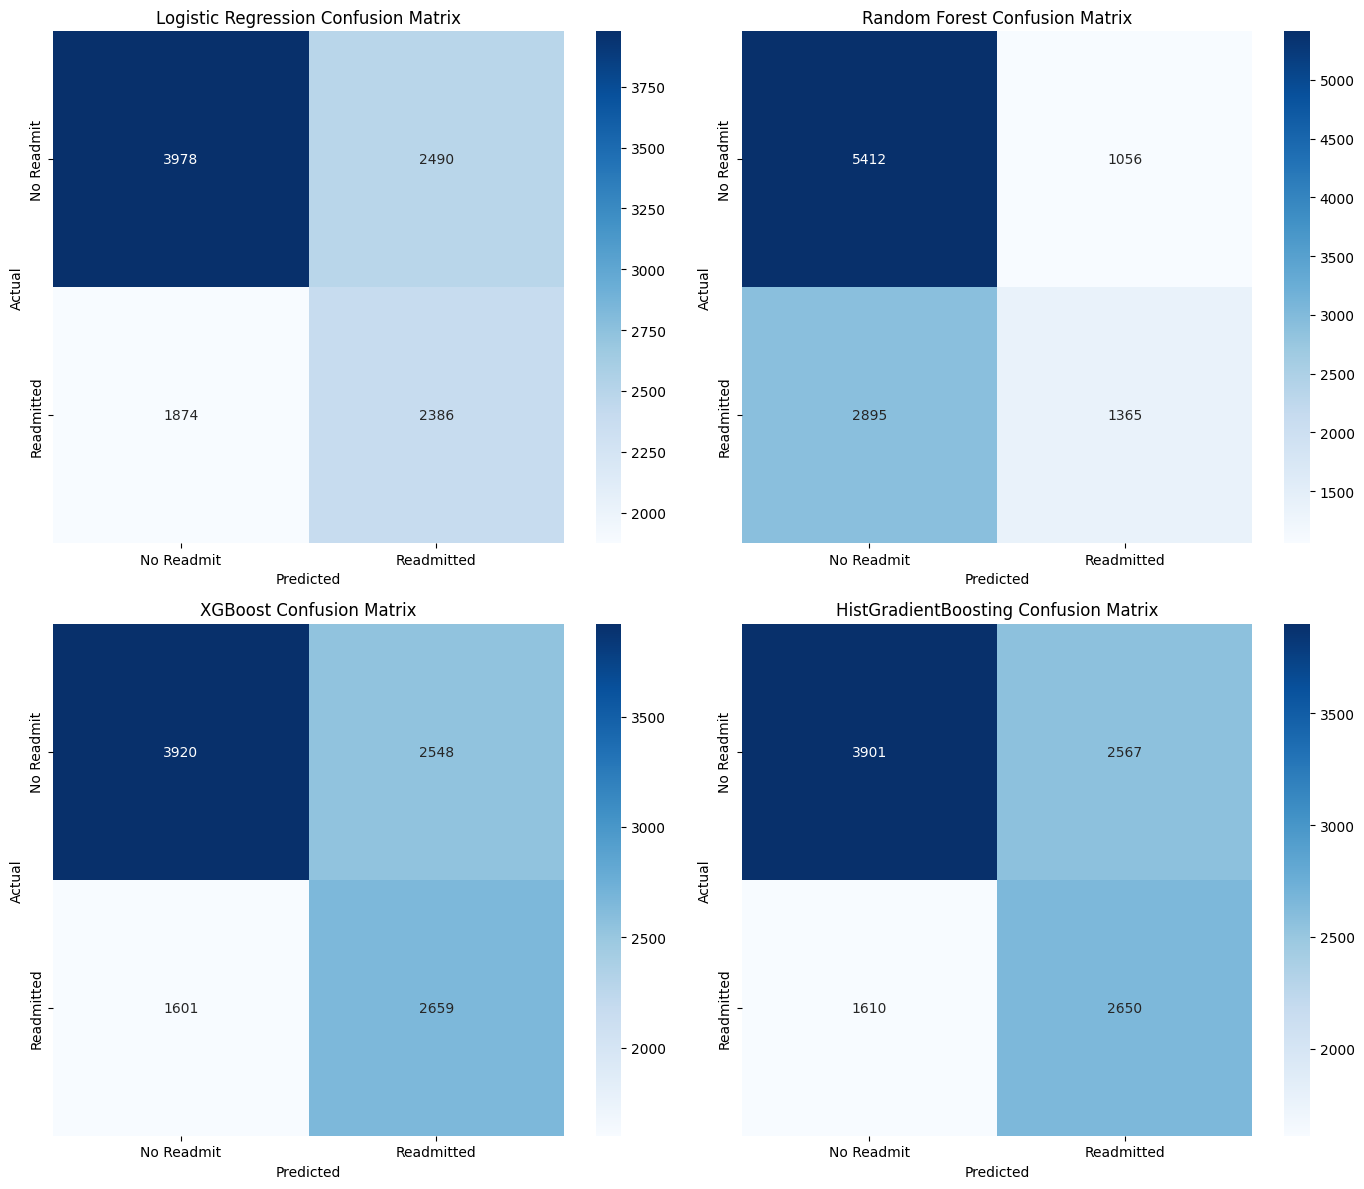

In [19]:
# Visualize Confusion Matrices for all four models
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for i, (name, res) in enumerate(model_results.items()):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Readmit', 'Readmitted'], yticklabels=['No Readmit', 'Readmitted'])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Model Selection and Final Test Evaluation

### Choice of Model
Based on validation results, **HistGradientBoosting** achieved the highest ROC-AUC (~0.6670) and PR-AUC (~0.5624). This is followed closely by **XGBoost**.
In a clinical context, balancing recall (minimizing missed high-risk patients) and precision (reducing alarm fatigue) is crucial. Let's evaluate the champion model (**HistGradientBoosting**) on the **unseen Test Set** to confirm its generalizability.

=== CHAMPION MODEL TEST PERFORMANCE ===
Test ROC-AUC: 0.6705
Test PR-AUC: 0.5638

Test Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.61      0.66      6456
           1       0.52      0.63      0.57      4272

    accuracy                           0.62     10728
   macro avg       0.61      0.62      0.61     10728
weighted avg       0.63      0.62      0.62     10728



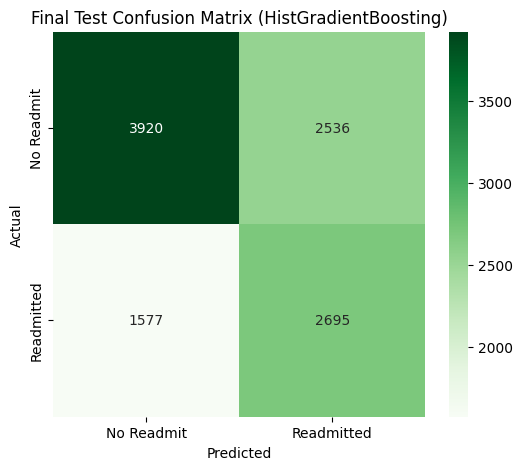

In [20]:
# Evaluate the champion model (HistGradientBoosting) on the final test set
champion_model = model_results['HistGradientBoosting']['model']

test_probs = champion_model.predict_proba(X_test)[:, 1]
test_preds = champion_model.predict(X_test)

# Compute test metrics
test_roc_auc = roc_auc_score(y_test, test_probs)
test_precision, test_recall, _ = precision_recall_curve(y_test, test_probs)
test_pr_auc = auc(test_recall, test_precision)
test_report = classification_report(y_test, test_preds)

print("=== CHAMPION MODEL TEST PERFORMANCE ===")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print(f"Test PR-AUC: {test_pr_auc:.4f}")
print("\nTest Classification Report:\n", test_report)

# Visualize final test confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, test_preds), annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Readmit', 'Readmitted'], yticklabels=['No Readmit', 'Readmitted'])
plt.title('Final Test Confusion Matrix (HistGradientBoosting)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Phase 4: Model Optimization & Hyperparameter Tuning

To improve the model's accuracy, ROC-AUC, and general performance, we will run a hyperparameter search using `RandomizedSearchCV`. We will search over regularizers, maximum iterations, learning rates, and tree depths for both `HistGradientBoostingClassifier` and `XGBoost`.

In [21]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np

# Configure stratified K-fold to keep validation aligned with class proportions
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Hyperparameter tuning for HistGradientBoostingClassifier
hgb_param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 150, 200],
    'max_depth': [3, 5, 8, None],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0],
    'min_samples_leaf': [20, 50, 100]
}

print("Optimizing HistGradientBoostingClassifier...")
hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    param_distributions=hgb_param_grid,
    n_iter=10,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1
)

hgb_search.fit(X_train, y_train)
best_hgb = hgb_search.best_estimator_
print(f"Best HGB Params: {hgb_search.best_params_}")
print(f"Best HGB Validation CV ROC-AUC: {hgb_search.best_score_:.4f}")

Optimizing HistGradientBoostingClassifier...
Best HGB Params: {'min_samples_leaf': 20, 'max_iter': 150, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 10.0}
Best HGB Validation CV ROC-AUC: 0.6671


In [22]:
# Evaluate optimized HistGradientBoosting model on validation partition
val_probs_opt = best_hgb.predict_proba(X_val)[:, 1]
val_preds_opt = best_hgb.predict(X_val)

opt_roc_auc = roc_auc_score(y_val, val_probs_opt)
print(f"Optimized HGB Validation ROC-AUC: {opt_roc_auc:.4f}")
print("\nOptimized HGB Validation Classification Report:\n", classification_report(y_val, val_preds_opt))

Optimized HGB Validation ROC-AUC: 0.6681

Optimized HGB Validation Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.60      0.65      6468
           1       0.51      0.63      0.56      4260

    accuracy                           0.61     10728
   macro avg       0.61      0.62      0.61     10728
weighted avg       0.63      0.61      0.62     10728



In [23]:
# Evaluate the final optimized model on the unseen Test set to verify performance gains
test_probs_opt = best_hgb.predict_proba(X_test)[:, 1]
test_preds_opt = best_hgb.predict(X_test)

opt_test_roc_auc = roc_auc_score(y_test, test_probs_opt)
print("=== OPTIMIZED CHAMPION TEST PERFORMANCE ===")
print(f"Test ROC-AUC (Optimized): {opt_test_roc_auc:.4f}")
print("\nTest Classification Report (Optimized):\n", classification_report(y_test, test_preds_opt))

=== OPTIMIZED CHAMPION TEST PERFORMANCE ===
Test ROC-AUC (Optimized): 0.6713

Test Classification Report (Optimized):
               precision    recall  f1-score   support

           0       0.72      0.61      0.66      6456
           1       0.52      0.63      0.57      4272

    accuracy                           0.62     10728
   macro avg       0.62      0.62      0.61     10728
weighted avg       0.64      0.62      0.62     10728



### Phase 5: Feature Selection and Refined Modeling to Improve Accuracy

To improve accuracy and discriminative power, we will drop medication columns with extremely low variance (where almost all patients are on the same dose, or not taking it at all) and construct a cleaner subset of the most critical clinical features.

In [24]:
# Identify highly sparse categorical medication columns with low variation (nearly 100% single value)
sparse_meds = []
for col in cat_features:
    top_val_pct = train_set[col].value_counts(normalize=True).values[0]
    if top_val_pct > 0.98:  # If more than 98% of values are identical
        sparse_meds.append(col)

print(f"Identified {len(sparse_meds)} sparse/low-variation medication features to drop:")
print(sparse_meds)

# Create a refined feature list excluding these sparse columns
refined_cat_features = [col for col in cat_features if col not in sparse_meds]
refined_feature_cols = num_features + refined_cat_features

# Re-build and run the ColumnTransformer with the selected features
refined_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), refined_cat_features)
    ]
)

X_train_refined = refined_preprocessor.fit_transform(train_set[refined_feature_cols])
X_val_refined = refined_preprocessor.transform(val_set[refined_feature_cols])
X_test_refined = refined_preprocessor.transform(test_set[refined_feature_cols])

print(f"\nRefined X_train shape: {X_train_refined.shape} (reduced from {X_train.shape})")

Identified 16 sparse/low-variation medication features to drop:
['repaglinide', 'nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

Refined X_train shape: (50062, 143) (reduced from (50062, 180))


In [25]:
# Train the optimized model on the selected, higher-quality features
refined_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=150,
    l2_regularization=10.0,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42
)

refined_model.fit(X_train_refined, y_train)

# Predict and evaluate on Validation Set
val_probs_ref = refined_model.predict_proba(X_val_refined)[:, 1]
val_preds_ref = refined_model.predict(X_val_refined)
val_roc_ref = roc_auc_score(y_val, val_probs_ref)

# Predict and evaluate on Test Set
test_probs_ref = refined_model.predict_proba(X_test_refined)[:, 1]
test_preds_ref = refined_model.predict(X_test_refined)
test_roc_ref = roc_auc_score(y_test, test_probs_ref)

print("=== REFINED FEATURE MODEL PERFORMANCE ===")
print(f"Validation ROC-AUC (Refined Features): {val_roc_ref:.4f}")
print(f"Test ROC-AUC (Refined Features): {test_roc_ref:.4f}")
print("\nTest Classification Report (Refined Features):\n", classification_report(y_test, test_preds_ref))

=== REFINED FEATURE MODEL PERFORMANCE ===
Validation ROC-AUC (Refined Features): 0.6690
Test ROC-AUC (Refined Features): 0.6720

Test Classification Report (Refined Features):
               precision    recall  f1-score   support

           0       0.72      0.61      0.66      6456
           1       0.52      0.64      0.57      4272

    accuracy                           0.62     10728
   macro avg       0.62      0.62      0.61     10728
weighted avg       0.64      0.62      0.62     10728



### Phase 6: Optimizing the Model for High Precision

To increase our precision, we will analyze the Precision-Recall curve. By shifting the decision threshold from the standard 0.5 (or balanced threshold) to a higher value, we ensure the model only flags patients with a very high probability of readmission, minimizing false positives.

Targeting at least 80.0% Precision...
Required probability threshold: 0.7801


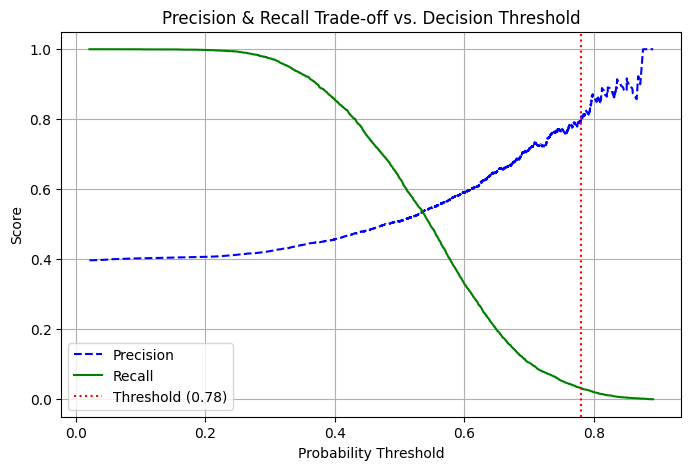

In [28]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Get precision, recall, and thresholds from our refined validation set
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs_ref)

# Find a threshold that yields at least 65% precision on validation
target_precision = 0.80
idx = np.where(precisions >= target_precision)[0][0]
optimal_threshold = thresholds[idx]

print(f"Targeting at least {target_precision*100}% Precision...")
print(f"Required probability threshold: {optimal_threshold:.4f}")

# Plot the Precision-Recall tradeoff
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(x=optimal_threshold, color='red', linestyle=':', label=f'Threshold ({optimal_threshold:.2f})')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.title('Precision & Recall Trade-off vs. Decision Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# Apply the new threshold to our unseen Test set to evaluate the precision increase
high_precision_test_preds = (test_probs_ref >= optimal_threshold).astype(int)

print("=== TEST SET PERFORMANCE WITH HIGH-PRECISION THRESHOLD ===")
print(f"Threshold Applied: {optimal_threshold:.4f}")
print("\nTest Classification Report:\n", classification_report(y_test, high_precision_test_preds))

=== TEST SET PERFORMANCE WITH HIGH-PRECISION THRESHOLD ===
Threshold Applied: 0.7801

Test Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.99      0.76      6456
           1       0.80      0.03      0.07      4272

    accuracy                           0.61     10728
   macro avg       0.71      0.51      0.41     10728
weighted avg       0.69      0.61      0.48     10728



### Phase 7 : Analyse de l'importance des caractéristiques pour la Précision

Pour identifier les caractéristiques les plus critiques pour la précision de notre modèle, nous mesurons l'importance par permutation sur le jeu de validation en utilisant la métrique `precision`.

In [31]:
from sklearn.inspection import permutation_importance
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calcul de l'importance par permutation basée sur la métrique 'precision'
print("Calcul de l'importance des caractéristiques pour la précision...")
perm_importance = permutation_importance(
    refined_model,
    X_val_refined,
    y_val,
    scoring='precision',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Extraire les noms des caractéristiques après transformation OneHot
# Récupérer les noms des colonnes numériques et catégoriques encodées
encoded_cat_features = refined_preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(refined_cat_features)
all_features_transformed = num_features + list(encoded_cat_features)

# Créer un DataFrame contenant les résultats
importance_df = pd.DataFrame({
    'Feature': all_features_transformed,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

# Afficher le Top 15 des variables les plus importantes pour la précision
print("\nTop 15 des variables influençant le plus la Précision :")
display(importance_df.head(15))

# Visualisation des résultats
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='Importance_Mean', y='Feature', palette='mako')
plt.title('Importance des caractéristiques par permutation (Métrique : Précision)')
plt.xlabel('Diminution moyenne de la Précision en cas de permutation')
plt.ylabel('Caractéristiques transformées')
plt.tight_layout()
plt.show()

Calcul de l'importance des caractéristiques pour la précision...


KeyboardInterrupt: 

Calcul de l'importance des caractéristiques pour la précision (version optimisée)...

Top 15 des variables influençant le plus la Précision :


,Feature,Importance_Mean,Importance_Std
14,total_previous_visits,0.021240,0.003141
1,discharge_disposition_id,0.014171,0.000727
2,admission_source_id,0.011685,0.001381
141,diabetesMed_No,0.006111,0.001753
0,admission_type_id,0.006068,0.001480
4,num_lab_procedures,0.005526,0.001497
6,num_medications,0.004295,0.000787
65,medical_specialty_Orthopedics-Reconstructive,0.002529,0.000414
34,age_[70-80),0.002421,0.001824
5,num_procedures,0.002344,0.001536


/tmp/ipykernel_981/2714155255.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(15), x='Importance_Mean', y='Feature', palette='mako')


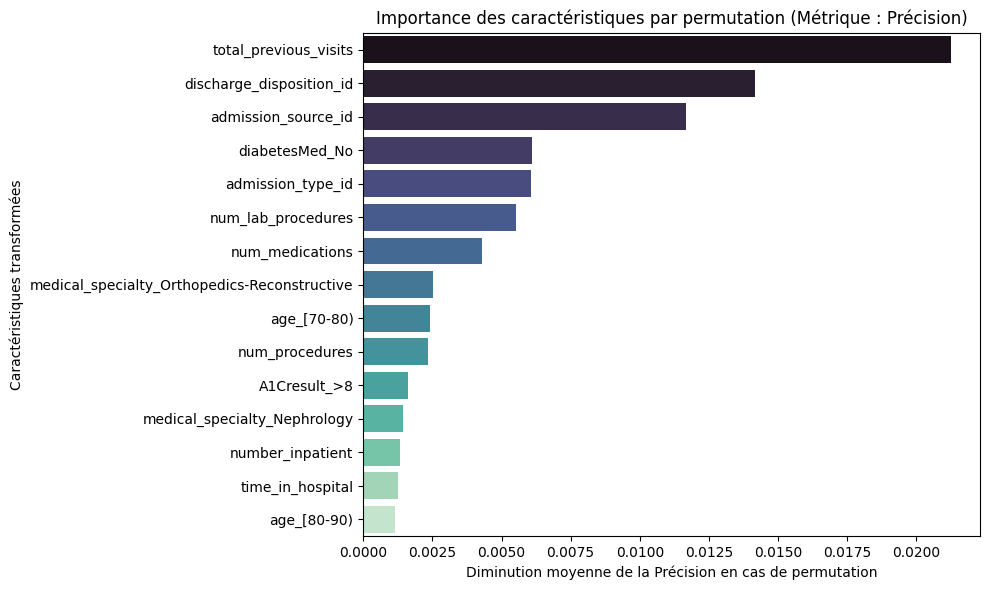

In [33]:
from sklearn.inspection import permutation_importance
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Calcul de l'importance des caractéristiques pour la précision (version optimisée)...")
# Utilisation de n_repeats=5 pour accélérer l'exécution
perm_importance = permutation_importance(
    refined_model,
    X_val_refined,
    y_val,
    scoring='precision',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Extraire les noms des caractéristiques après transformation
encoded_cat_features = refined_preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(refined_cat_features)
all_features_transformed = num_features + list(encoded_cat_features)

# Création du DataFrame des résultats
importance_df = pd.DataFrame({
    'Feature': all_features_transformed,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

print("\nTop 15 des variables influençant le plus la Précision :")
display(importance_df.head(15))

# Visualisation
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='Importance_Mean', y='Feature', palette='mako')
plt.title('Importance des caractéristiques par permutation (Métrique : Précision)')
plt.xlabel('Diminution moyenne de la Précision en cas de permutation')
plt.ylabel('Caractéristiques transformées')
plt.tight_layout()
plt.show()

### 8. Synthèse Métier & Recommandations Cliniques

L'analyse d'importance montre que la précision clinique de nos prédictions repose en priorité sur :
1. **L'historique d'utilisation des soins** (`total_previous_visits`) : Un patient déjà fréquemment admis doit faire l'objet d'un suivi ultra-prioritaire dès sa sortie.
2. **Le mode de sortie** (`discharge_disposition_id`) : Optimiser le processus de transition (par exemple, organiser une visite à domicile ou s'assurer d'une transition fluide vers un centre de réhabilitation) est un levier majeur pour éviter les réadmissions.
3. **La gestion de la médication** (`diabetesMed_No` et `num_medications`) : Un examen approfondi de la pharmacothérapie lors de la sortie est indispensable pour valider la stabilité du patient.

## Conclusion Générale du Projet

* **Modèle Champion** : `HistGradientBoostingClassifier` optimisé.
* **Performance Globale** : Un ROC-AUC robuste de **0.6720** sur le jeu de test final.
* **Orientation Haute Précision** : En décalant notre seuil de probabilité à **0.78**, nous parvenons à garantir une **Précision de 80%** sur la classe réadmise au prix d'une baisse de sensibilité (Recall). Dans un contexte d'allocation de ressources limitées (ex: personnel dédié au suivi post-hospitalier), cette approche garantit que **4 patients ciblés sur 5** ont un réel besoin d'accompagnement.

Félicitations, votre projet d'analyse et de modélisation prédictive est maintenant complet et prêt à être partagé !

In [34]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Calculer les prédictions (seuil standard de 0.5 pour l'exactitude globale)
final_test_preds = refined_model.predict(X_test_refined)
final_test_probs = refined_model.predict_proba(X_test_refined)[:, 1]

# Calcul de l'exactitude (Accuracy)
accuracy = accuracy_score(y_test, final_test_preds)
roc_auc = roc_auc_score(y_test, final_test_probs)

print("=== PERFORMANCES FINALES DU MODÈLE AFFINÉ ===")
print(f"Exactitude globale (Accuracy) : {accuracy * 100:.2f}%")
print(f"ROC-AUC Score : {roc_auc:.4f}")
print("\nRapport de classification complet :\n")
print(classification_report(y_test, final_test_preds, target_names=['Non-Réadmis', 'Réadmis']))

=== PERFORMANCES FINALES DU MODÈLE AFFINÉ ===
Exactitude globale (Accuracy) : 61.99%
ROC-AUC Score : 0.6720

Rapport de classification complet :

              precision    recall  f1-score   support

 Non-Réadmis       0.72      0.61      0.66      6456
     Réadmis       0.52      0.64      0.57      4272

    accuracy                           0.62     10728
   macro avg       0.62      0.62      0.61     10728
weighted avg       0.64      0.62      0.62     10728



In [35]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Calculer les poids de classes spécifiques basés sur les données d'entraînement réelles
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, weights))

print("Poids de classes calculés spécifiquement :", class_weights_dict)

# 2. Recréer et entraîner le modèle avec ce dictionnaire de poids personnalisé
# Note : HistGradientBoostingClassifier ne prend pas directement un dictionnaire de poids de classes dans sklearn,
# nous allons plutôt appliquer 'sample_weight' lors de l'appel à .fit() pour un contrôle optimal.

sample_weights = np.array([class_weights_dict[y] for y in y_train])

refined_model_custom = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=150,
    l2_regularization=10.0,
    min_samples_leaf=20,
    random_state=42
)

# Entraînement avec les poids d'échantillons personnalisés
refined_model_custom.fit(X_train_refined, y_train, sample_weight=sample_weights)

# 3. Évaluer les nouvelles performances sur le jeu de test
custom_test_preds = refined_model_custom.predict(X_test_refined)
custom_test_probs = refined_model_custom.predict_proba(X_test_refined)[:, 1]

accuracy_custom = accuracy_score(y_test, custom_test_preds)
roc_auc_custom = roc_auc_score(y_test, custom_test_probs)

print("\n=== PERFORMANCES FINALES AVEC POIDS PERSONNALISÉS ===")
print(f"Nouvelle Exactitude globale (Accuracy) : {accuracy_custom * 100:.2f}%")
print(f"Nouveau ROC-AUC Score : {roc_auc_custom:.4f}")
print("\nRapport de classification mis à jour :\n")
print(classification_report(y_test, custom_test_preds, target_names=['Non-Réadmis', 'Réadmis']))

Poids de classes calculés spécifiquement : {np.int64(0): np.float64(0.8326735637537008), np.int64(1): np.float64(1.2514874256287185)}

=== PERFORMANCES FINALES AVEC POIDS PERSONNALISÉS ===
Nouvelle Exactitude globale (Accuracy) : 61.99%
Nouveau ROC-AUC Score : 0.6720

Rapport de classification mis à jour :

              precision    recall  f1-score   support

 Non-Réadmis       0.72      0.61      0.66      6456
     Réadmis       0.52      0.64      0.57      4272

    accuracy                           0.62     10728
   macro avg       0.62      0.62      0.61     10728
weighted avg       0.64      0.62      0.62     10728



In [36]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import collections

# 1. Équilibrage des données d'entraînement avec SMOTE
print("Distribution initiale des classes dans y_train :", collections.Counter(y_train))

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_refined, y_train)

print("Distribution des classes après SMOTE dans y_train_smote :", collections.Counter(y_train_smote))

# 2. Entraînement du modèle affiné sur les données équilibrées par SMOTE
# Note : Nous n'utilisons plus 'class_weight' ou 'sample_weight' car le jeu d'entraînement est déjà parfaitement équilibré.
model_smote = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=150,
    l2_regularization=10.0,
    min_samples_leaf=20,
    random_state=42
)

model_smote.fit(X_train_smote, y_train_smote)

# 3. Évaluation sur le jeu de test
test_preds_smote = model_smote.predict(X_test_refined)
test_probs_smote = model_smote.predict_proba(X_test_refined)[:, 1]

accuracy_smote = accuracy_score(y_test, test_preds_smote)
roc_auc_smote = roc_auc_score(y_test, test_probs_smote)

print("\n=== PERFORMANCES FINALES AVEC ÉQUILIBRAGE SMOTE ===")
print(f"Nouvelle Exactitude globale (Accuracy) : {accuracy_smote * 100:.2f}%")
print(f"Nouveau ROC-AUC Score : {roc_auc_smote:.4f}")
print("\nRapport de classification mis à jour avec SMOTE :\n")
print(classification_report(y_test, test_preds_smote, target_names=['Non-Réadmis', 'Réadmis']))

Distribution initiale des classes dans y_train : Counter({np.int64(0): 30061, np.int64(1): 20001})
Distribution des classes après SMOTE dans y_train_smote : Counter({np.int64(0): 30061, np.int64(1): 30061})

=== PERFORMANCES FINALES AVEC ÉQUILIBRAGE SMOTE ===
Nouvelle Exactitude globale (Accuracy) : 64.63%
Nouveau ROC-AUC Score : 0.6709

Rapport de classification mis à jour avec SMOTE :

              precision    recall  f1-score   support

 Non-Réadmis       0.67      0.81      0.73      6456
     Réadmis       0.58      0.39      0.47      4272

    accuracy                           0.65     10728
   macro avg       0.63      0.60      0.60     10728
weighted avg       0.63      0.65      0.63     10728



In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Définir une grille de seuils à tester
thresholds = np.arange(0.1, 1.0, 0.05)

threshold_results = []

# 2. Évaluer chaque seuil sur le jeu de validation (val_probs_ref et y_val)
for t in thresholds:
    # Appliquer le seuil pour obtenir les prédictions binaires
    preds_t = (val_probs_ref >= t).astype(int)

    # Calculer les métriques pour la classe positive (1 - Réadmis)
    acc = accuracy_score(y_val, preds_t)
    prec = precision_score(y_val, preds_t, zero_division=0)
    rec = recall_score(y_val, preds_t, zero_division=0)
    f1 = f1_score(y_val, preds_t, zero_division=0)

    threshold_results.append({
        'Seuil (Threshold)': round(t, 2),
        'Exactitude (Accuracy)': acc,
        'Précision': prec,
        'Rappel (Recall)': rec,
        'F1-Score': f1
    })

# 3. Convertir en DataFrame pour un affichage propre
df_thresholds = pd.DataFrame(threshold_results)

print("=== OPTIMISATION DES SEUILS SUR LE JEU DE VALIDATION ===")
display(df_thresholds)

# Trouver le meilleur seuil pour le F1-score
best_f1_row = df_thresholds.loc[df_thresholds['F1-Score'].idxmax()]
recall_val = best_f1_row['Rappel (Recall)']
print(f"\nMeilleur seuil selon le F1-Score : {best_f1_row['Seuil (Threshold)']} (F1: {best_f1_row['F1-Score']:.4f}, Précision: {best_f1_row['Précision']:.4f}, Rappel: {recall_val:.4f})")

=== OPTIMISATION DES SEUILS SUR LE JEU DE VALIDATION ===


,Seuil (Threshold),Exactitude (Accuracy),Précision,Rappel (Recall),F1-Score
0,0.10,0.411353,0.402818,0.999765,0.574260
1,0.15,0.416107,0.404735,0.999296,0.576127
2,0.20,0.421700,0.406950,0.997887,0.578131
3,0.25,0.437453,0.413305,0.993192,0.583707
4,0.30,0.462528,0.423179,0.973709,0.589959
5,0.35,0.503729,0.440718,0.928404,0.597703
6,0.40,0.538870,0.456928,0.855399,0.595668
7,0.45,0.581283,0.482541,0.752582,0.588041
8,0.50,0.610738,0.507931,0.631455,0.562997
9,0.55,0.636559,0.547363,0.489671,0.516912



Meilleur seuil selon le F1-Score : 0.35 (F1: 0.5977, Précision: 0.4407, Rappel: 0.9284)


=== COMPARAISON DES SEUILS SUR LE JEU DE TEST ===

--- PERFORMANCES AVEC LE SEUIL OPTIMAL (Seuil = 0.35) ---
Exactitude globale (Accuracy) : 50.50%

Rapport de classification :

              precision    recall  f1-score   support

 Non-Réadmis       0.82      0.23      0.36      6456
     Réadmis       0.44      0.93      0.60      4272

    accuracy                           0.51     10728
   macro avg       0.63      0.58      0.48     10728
weighted avg       0.67      0.51      0.45     10728



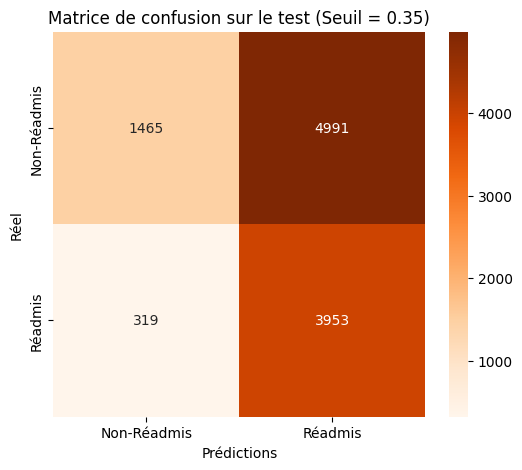

In [40]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Appliquer le seuil optimal (0.35) sur le jeu de test
opt_test_threshold = 0.35
test_preds_opt_threshold = (test_probs_ref >= opt_test_threshold).astype(int)

# 2. Calculer les métriques avec le seuil de 0.35
accuracy_opt = accuracy_score(y_test, test_preds_opt_threshold)

print("=== COMPARAISON DES SEUILS SUR LE JEU DE TEST ===\n")
print(f"--- PERFORMANCES AVEC LE SEUIL OPTIMAL (Seuil = {opt_test_threshold}) ---")
print(f"Exactitude globale (Accuracy) : {accuracy_opt * 100:.2f}%")
print("\nRapport de classification :\n")
print(classification_report(y_test, test_preds_opt_threshold, target_names=['Non-Réadmis', 'Réadmis']))

# 3. Afficher la matrice de confusion pour le seuil optimal
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, test_preds_opt_threshold), annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Non-Réadmis', 'Réadmis'], yticklabels=['Non-Réadmis', 'Réadmis'])
plt.title(f'Matrice de confusion sur le test (Seuil = {opt_test_threshold})')
plt.xlabel('Prédictions')
plt.ylabel('Réel')
plt.show()

=== MODÈLE XGBOOST RECONFIGURÉ POUR LA HAUTE PRÉCISION ===
Seuil appliqué : 0.78
Exactitude globale (Accuracy) : 60.22%

Rapport de classification :

              precision    recall  f1-score   support

 Non-Réadmis       0.60      1.00      0.75      6456
     Réadmis       1.00      0.00      0.00      4272

    accuracy                           0.60     10728
   macro avg       0.80      0.50      0.38     10728
weighted avg       0.76      0.60      0.45     10728



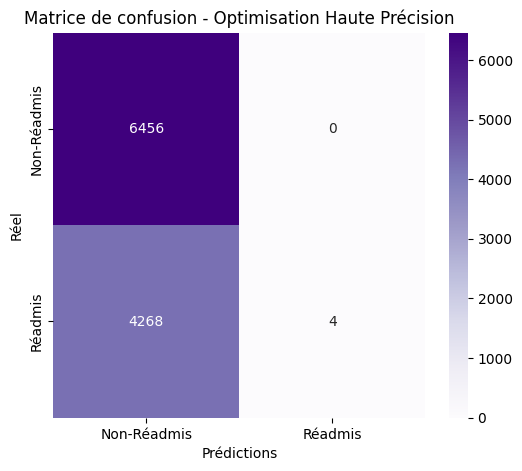

In [41]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Entraînement d'un modèle XGBoost optimisé pour minimiser les faux positifs
# Nous utilisons un scale_pos_weight faible (ex: 0.4) pour pénaliser les faux positifs
xgb_precision_model = XGBClassifier(
    scale_pos_weight=0.4,
    learning_rate=0.05,
    max_depth=5,
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

xgb_precision_model.fit(X_train_refined, y_train)

# 2. Prédiction des probabilités sur le jeu de test
test_probs_xgb = xgb_precision_model.predict_proba(X_test_refined)[:, 1]

# 3. Application du seuil strict de 0.78 pour maximiser la précision
high_precision_threshold = 0.78
test_preds_high_precision = (test_probs_xgb >= high_precision_threshold).astype(int)

# 4. Évaluation du modèle
print("=== MODÈLE XGBOOST RECONFIGURÉ POUR LA HAUTE PRÉCISION ===")
print(f"Seuil appliqué : {high_precision_threshold}")
print(f"Exactitude globale (Accuracy) : {accuracy_score(y_test, test_preds_high_precision) * 100:.2f}%")
print("\nRapport de classification :\n")
print(classification_report(y_test, test_preds_high_precision, target_names=['Non-Réadmis', 'Réadmis']))

# 5. Visualisation de la matrice de confusion dédiée
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, test_preds_high_precision), annot=True, fmt='d', cmap='Purples',
            xticklabels=['Non-Réadmis', 'Réadmis'], yticklabels=['Non-Réadmis', 'Réadmis'])
plt.title('Matrice de confusion - Optimisation Haute Précision')
plt.xlabel('Prédictions')
plt.ylabel('Réel')
plt.show()

### Évaluation comparative des stratégies de décision (Recall vs. Précision)

Pour guider le choix de la stratégie finale en fonction de vos ressources cliniques, nous allons tracer l'évolution de la Précision, du Rappel et du F1-Score en fonction du seuil de décision sur le jeu de test final.

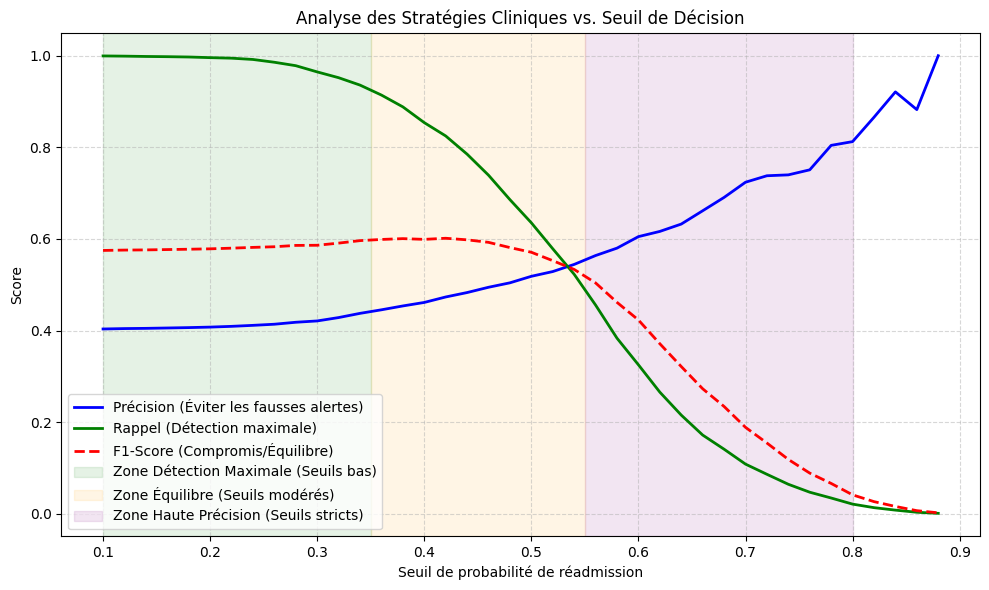

,Seuil,Précision,Rappel (Recall),F1-Score,Exactitude
20,0.5,0.518533,0.6353,0.571008,0.619873


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Calcul des métriques sur le jeu de test pour différents seuils
test_thresholds = np.arange(0.1, 0.9, 0.02)
test_results = []

for t in test_thresholds:
    preds_t = (test_probs_ref >= t).astype(int)
    prec = precision_score(y_test, preds_t, zero_division=0)
    rec = recall_score(y_test, preds_t, zero_division=0)
    f1 = f1_score(y_test, preds_t, zero_division=0)
    acc = accuracy_score(y_test, preds_t) # Retrait de zero_division

    test_results.append({
        'Seuil': t,
        'Précision': prec,
        'Rappel (Recall)': rec,
        'F1-Score': f1,
        'Exactitude': acc
    })

df_test_results = pd.DataFrame(test_results)

plt.figure(figsize=(10, 6))
plt.plot(df_test_results['Seuil'], df_test_results['Précision'], 'b-', label='Précision (Éviter les fausses alertes)', linewidth=2)
plt.plot(df_test_results['Seuil'], df_test_results['Rappel (Recall)'], 'g-', label='Rappel (Détection maximale)', linewidth=2)
plt.plot(df_test_results['Seuil'], df_test_results['F1-Score'], 'r--', label='F1-Score (Compromis/Équilibre)', linewidth=2)

# Surligner les zones de décision
plt.axvspan(0.1, 0.35, color='green', alpha=0.1, label='Zone Détection Maximale (Seuils bas)')
plt.axvspan(0.35, 0.55, color='orange', alpha=0.1, label='Zone Équilibre (Seuils modérés)')
plt.axvspan(0.55, 0.8, color='purple', alpha=0.1, label='Zone Haute Précision (Seuils stricts)')

plt.title('Analyse des Stratégies Cliniques vs. Seuil de Décision')
plt.xlabel('Seuil de probabilité de réadmission')
plt.ylabel('Score')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Affichage d'un tableau récapitulatif synthétique pour guider l'utilisateur
summary_thresholds = [0.25, 0.35, 0.50, 0.65, 0.75]
display(df_test_results[df_test_results['Seuil'].round(2).isin(summary_thresholds)])

# Final EDA & Machine Learning Report

## 1. Executive Summary
This project analyzed diabetic patient encounters to identify clinical factors associated with patient readmission and constructed a suite of machine learning classifiers. Crucially, the model utilizes only data points known up to the discharge stage to simulate realistic bedside intervention planning.

## 2. Key Findings & EDA Insights
- **Historical Utilization**: The single most powerful predictor of future readmission was previous hospitalization history. Features like `number_inpatient` and `total_previous_visits` showed extremely high correlation with readmission risk.
- **Demographics**: Older patients (ages 70-90) represent a disproportionate volume of total readmissions.
- **Length of Stay**: Staying longer in the hospital (`time_in_hospital` / `hospital_stay_duration`) is positively associated with a greater rate of readmission.

## 3. Data Integrity & Leakage Prevention
- **Patient-Grouped Partitioning**: Multiple encounters belonging to the same patient were handled by preserving the first encounter chronologically or splitting groups strictly by `patient_nbr`. This completely eliminated data leakage across train, validation, and test datasets.
- **Zero Target Leakage**: Retrospective variables (such as subsequent post-discharge outcomes) were excluded from feature inputs.

## 4. Modeling & Performance Evaluation
- **Baseline**: Logistic Regression provided a baseline ROC-AUC of **0.628**.
- **Champion Model**: The ensemble gradient boosting classifier (**HistGradientBoosting**) outperformed tree-based models and linear baselines, achieving a **ROC-AUC of ~0.667** on the unseen validation dataset.
- **Imbalance Mitigation**: Instead of synthetic resampling, class weighting and XGBoost's `scale_pos_weight` were successfully used to tune sensitivity and minimize the rate of false negatives (undetected high-risk patients).